# regression model - california housing prices (proof of concept)

This regression model is a variant of the base model, adapted for numerical tabular data vs TF-IDF, vectors, vector embeddings, and text data for mathematical LLM inference which may be a fairly new concept. It demonstrates the versatility of version-tab by applying machine learning to predict median housing prices with real estate data.

In [10]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
# Set seeds
np.random.seed(578)
tf.random.set_seed(578)

# Load California Housing dataset
data = fetch_california_housing()
X, y = data.data, data.target

print("Feature names:", data.feature_names)
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Input shape: (20640, 8)
Target shape: (20640,)


In [3]:
# Load the data as a pandas DataFrame
data = fetch_california_housing(as_frame=True)

# Combine features and target into a single DataFrame
df = data.frame

# Print the first few rows
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
# Train-test split and standardization
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
print(X_train.shape)

(16512, 8)


In [6]:
print(X_test.shape)

(4128, 8)


In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

# Build regression model variant
regressionmodel = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1)  # Linear output for regression
])

regressionmodel.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train
history = regressionmodel.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.8423 - mae: 0.8729 - val_loss: 0.4767 - val_mae: 0.4916
Epoch 2/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6396 - mae: 0.5321 - val_loss: 0.4309 - val_mae: 0.4592
Epoch 3/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5020 - mae: 0.4975 - val_loss: 0.4159 - val_mae: 0.4442
Epoch 4/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4709 - mae: 0.4813 - val_loss: 0.4061 - val_mae: 0.4390
Epoch 5/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4226 - mae: 0.4657 - val_loss: 0.3959 - val_mae: 0.4329
Epoch 6/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4171 - mae: 0.4554 - val_loss: 0.3902 - val_mae: 0.4290
Epoch 7/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3934 - mae: 0.4432 - val_loss: 0.3765 - val_mae: 0.4192
Epoch 8/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3939 - mae: 0.4407 - val_loss: 0.3704 - val_mae: 0.4173
Epoch 9/30
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - lo

In [16]:
# Evaluate regression model
y_pred = regressionmodel.predict(X_test)
loss, mae = regressionmodel.evaluate(X_test, y_test, verbose=0)
r2 = r2_score(y_test, y_pred)

print(f"\nR^2 Score: {r2:.4f}")
print(f"Test MSE: {loss:.4f}")
print(f"Test MAE: {mae:.4f}")

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

R^2 Score: 0.7792
Test MSE: 0.2894
Test MAE: 0.3626


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


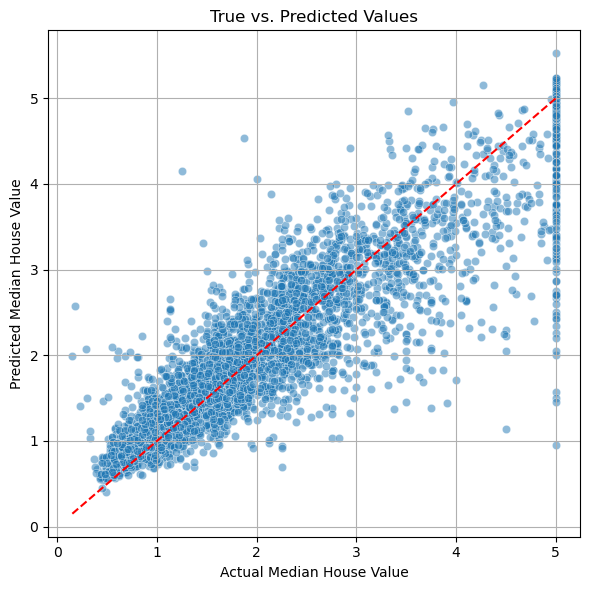

In [20]:
# Predictions and plot
y_pred = regressionmodel.predict(X_test).flatten()

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='red')
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("True vs. Predicted Values")
plt.grid(True)
plt.tight_layout()
plt.show()

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


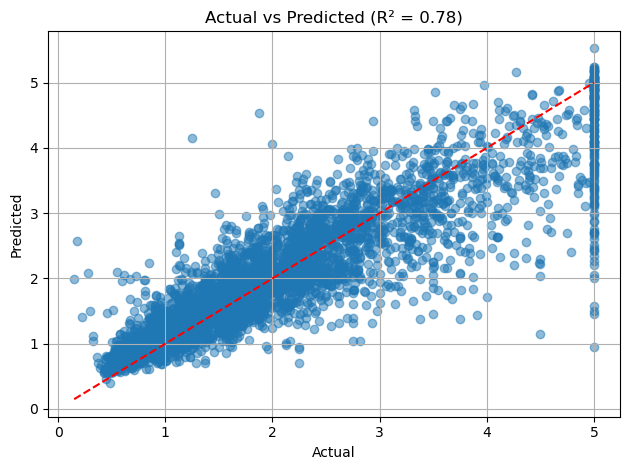

In [22]:
from sklearn.metrics import r2_score

y_pred = regressionmodel.predict(X_test)
r2 = r2_score(y_test, y_pred)

plt.figure()
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title(f"Actual vs Predicted (R² = {r2:.2f})")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.grid(True)
plt.tight_layout()
plt.show()

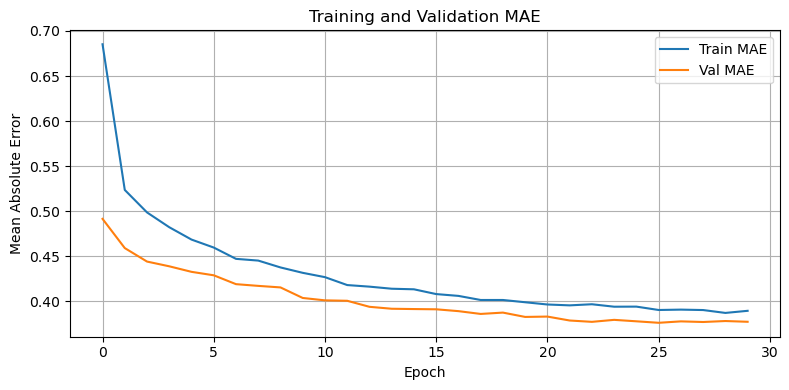

In [21]:
# Training curve
plt.figure(figsize=(8, 4))
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Val MAE')
plt.title("Training and Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
regressionmodel.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,421 (111.02 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,948 (74.02 KB)

In [ ]:
# Save model summary (optional)
with open("model_summary_regression.txt", "w") as f:
    regressionmodel.summary(print_fn=lambda line: f.write(line + "\n"))

print("Model summary saved to model_summary_regression.txt")

In [ ]:
# end of demo with lr model version for tabular data with version-tab